# Revisão de Python para a Aula 5 - Business Intelligence e Análise Preditiva

**Centro Universitário SENAC - Pós-graduação em Big Data - Prof. Pedro Ernesto da Silva Souza**

Este notebook revisa, em 30 a 40 minutos, o mínimo de Python necessário para acompanhar os laboratórios das Aulas 5 a 7 (regressão, árvores de decisão e redes neurais no Google Colab).
Não é preciso decorar nada: nos laboratórios, o código virá pronto e você completará apenas trechos marcados com `TODO`.

**Como usar o Colab**
- Cada bloco cinza é uma célula de código. Clique nela e pressione `Shift + Enter` para executar.
- A saída aparece logo abaixo da célula. Execute as células na ordem.
- O notebook fica salvo no seu Google Drive (Arquivo → Salvar uma cópia no Drive).
- Se algo der errado, use Ambiente de execução → Reiniciar sessão e execute de novo desde o início.

Leitura de apoio (gratuita, em português): DOWNEY, Allen. *Pense em Python*, caps. 1 a 3 (opcionais: 10 - Listas; 11 - Dicionários).

## 1. Variáveis, tipos e operações

In [1]:
# Variáveis não precisam de declaração de tipo
receita = 13591643.70      # float (número com casas decimais)
pedidos = 98666            # int (número inteiro)
empresa = "Olist"          # str (texto)
atrasado = False           # bool (verdadeiro ou falso)

ticket_medio = receita / pedidos
print("Ticket médio:", ticket_medio)
print("Ticket médio formatado: R$", round(ticket_medio, 2))
print(type(receita), type(pedidos), type(empresa), type(atrasado))

Ticket médio: 137.75407637889444
Ticket médio formatado: R$ 137.75
<class 'float'> <class 'int'> <class 'str'> <class 'bool'>


In [2]:
# f-strings: texto com valores dentro de chaves e formato após os dois-pontos
print(f"A {empresa} teve {pedidos:,} pedidos e receita de R$ {receita:,.2f}")
print(f"Ticket médio: R$ {ticket_medio:.2f}")
print(f"Percentual de frete: {2251909.54 / receita:.1%}")

A Olist teve 98,666 pedidos e receita de R$ 13,591,643.70
Ticket médio: R$ 137.75
Percentual de frete: 16.6%


## 2. Listas e dicionários (Downey, caps. 10 e 11)

In [3]:
# Lista: sequência ordenada; índices começam em 0
estados = ["SP", "RJ", "MG", "RS", "PR"]
print(estados[0], estados[-1], len(estados))
print(estados[1:3])          # fatia: do índice 1 até antes do 3

estados.append("SC")         # adiciona ao fim
print(estados)

# Laço for percorre os elementos
for uf in estados:
    print(uf, end=" ")
print()

# Compreensão de lista: cria uma lista nova a partir de outra
receita_mil = [5203, 1824, 1585, 750, 683, 521]
receita_milhoes = [valor / 1000 for valor in receita_mil]
print(receita_milhoes)

SP PR 5
['RJ', 'MG']
['SP', 'RJ', 'MG', 'RS', 'PR', 'SC']
SP RJ MG RS PR SC 
[5.203, 1.824, 1.585, 0.75, 0.683, 0.521]


In [4]:
# Dicionário: pares chave → valor
receita_por_uf = {"SP": 5202955.05, "RJ": 1824092.67, "MG": 1585308.03}
print(receita_por_uf["SP"])
receita_por_uf["RS"] = 750304.02          # inclui uma chave nova
print(receita_por_uf.keys())
print(receita_por_uf.get("AM", 0))        # get evita erro quando a chave não existe

for uf, valor in receita_por_uf.items():
    print(f"{uf}: R$ {valor:,.2f}")

5202955.05
dict_keys(['SP', 'RJ', 'MG', 'RS'])
0
SP: R$ 5,202,955.05
RJ: R$ 1,824,092.67
MG: R$ 1,585,308.03
RS: R$ 750,304.02


## 3. Condicionais e funções

In [5]:
def classificar_entrega(dias, prazo):
    """Devolve 'atrasada' se a entrega passou do prazo; senão, 'no prazo'."""
    if dias > prazo:
        return "atrasada"
    elif dias == prazo:
        return "no limite"
    else:
        return "no prazo"

print(classificar_entrega(12, 23))
print(classificar_entrega(30, 23))

# Aplicar a função a vários pedidos
entregas = [(8.4, 15.5), (26.0, 23.2), (10.2, 10.2)]
for dias, prazo in entregas:
    print(dias, prazo, "→", classificar_entrega(dias, prazo))

no prazo
atrasada
8.4 15.5 → no prazo
26.0 23.2 → atrasada
10.2 10.2 → no limite


## 4. Bibliotecas: numpy, pandas e matplotlib

Nos laboratórios usaremos quatro bibliotecas, todas já instaladas no Colab:
- `numpy` (np): vetores e operações numéricas;
- `pandas` (pd): tabelas (DataFrame), leitura de CSV, filtros e agrupamentos;
- `matplotlib` (plt): gráficos;
- `scikit-learn` (sklearn): modelos preditivos (Aula 5 em diante).

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

dias = np.array([8.4, 13.8, 9.3, 26.0, 10.2, 4.7, 16.9])
print("média:", dias.mean().round(2), "| mediana:", np.median(dias), "| máximo:", dias.max())
print("acima de 15 dias:", (dias > 15).sum(), "pedidos")

média: 12.76 | mediana: 10.2 | máximo: 26.0
acima de 15 dias: 2 pedidos


In [7]:
# DataFrame criado a partir de um dicionário (nos laboratórios virá de um CSV: pd.read_csv("arquivo.csv"))
pedidos = pd.DataFrame({
    "order_id": ["a1", "b2", "c3", "d4", "e5", "f6"],
    "customer_state": ["SP", "RJ", "SP", "AM", "MG", "SP"],
    "dias_entrega": [8.4, 13.8, 9.3, 26.0, 10.2, 4.7],
    "dias_estimados": [15.5, 19.1, 12.0, 23.2, 18.3, 10.0],
    "preco_total": [29.99, 118.70, 159.90, 45.00, 19.90, 89.00],
})
pedidos

,order_id,customer_state,dias_entrega,dias_estimados,preco_total
0,a1,SP,8.4,15.5,29.99
1,b2,RJ,13.8,19.1,118.70
2,c3,SP,9.3,12.0,159.90
3,d4,AM,26.0,23.2,45.00
4,e5,MG,10.2,18.3,19.90
5,f6,SP,4.7,10.0,89.00


In [8]:
# Inspeção rápida (os mesmos comandos abrem o laboratório da Aula 5)
print(pedidos.shape)            # (linhas, colunas)
print(pedidos.dtypes)           # tipo de cada coluna
pedidos.describe()              # estatísticas das colunas numéricas

(6, 5)
order_id              str
customer_state        str
dias_entrega      float64
dias_estimados    float64
preco_total       float64
dtype: object


,dias_entrega,dias_estimados,preco_total
count,6.000000,6.000000,6.000000
mean,12.066667,16.350000,77.081667
std,7.429581,4.863229,55.226099
min,4.700000,10.000000,19.900000
25%,8.625000,12.875000,33.742500
50%,9.750000,16.900000,67.000000
75%,12.900000,18.900000,111.275000
max,26.000000,23.200000,159.900000


In [9]:
# Nova coluna, filtro e agrupamento
pedidos["atrasado"] = (pedidos["dias_entrega"] > pedidos["dias_estimados"]).astype(int)
print(pedidos[pedidos["customer_state"] == "SP"])                 # filtro
print(pedidos.groupby("customer_state")["dias_entrega"].mean())    # média por estado
print("taxa de atraso:", pedidos["atrasado"].mean())

  order_id customer_state  dias_entrega  dias_estimados  preco_total  atrasado
0       a1             SP           8.4            15.5        29.99         0
2       c3             SP           9.3            12.0       159.90         0
5       f6             SP           4.7            10.0        89.00         0
customer_state
AM    26.000000
MG    10.200000
RJ    13.800000
SP     7.466667
Name: dias_entrega, dtype: float64
taxa de atraso: 0.16666666666666666


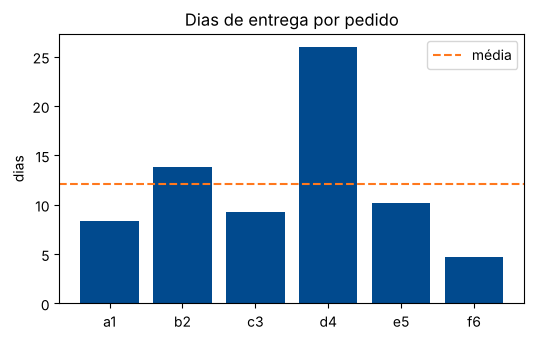

In [10]:
# Gráfico simples
plt.figure(figsize=(6, 3.5))
plt.bar(pedidos["order_id"], pedidos["dias_entrega"], color="#014A8E")
plt.axhline(pedidos["dias_entrega"].mean(), color="#FF781D", linestyle="--", label="média")
plt.title("Dias de entrega por pedido")
plt.ylabel("dias")
plt.legend()
plt.show()

## 5. Exercícios (10 minutos)

Resolva nas células abaixo. As soluções estão no fim do notebook.

1. Crie uma lista com os valores `[137.75, 120.40, 98.10, 155.00]` (ticket médio de quatro meses) e imprima a média com duas casas decimais.
2. Crie um dicionário com três categorias e suas receitas e imprima apenas a categoria de maior receita.
3. No DataFrame `pedidos`, selecione os pedidos atrasados (`atrasado == 1`) e mostre `order_id`, `customer_state` e `dias_entrega`.
4. Escreva uma função `faixa_preco(valor)` que devolva "baixo" (até 50), "médio" (até 150) ou "alto", e aplique-a à coluna `preco_total` com `pedidos["preco_total"].apply(faixa_preco)`.

In [2]:
# Exercício 1
tickets = [137.75, 120.40, 98.10, 155.00]
print(f"média: {sum(tickets) / len(tickets):.2f}")

média: 127.81


In [4]:
# Exercício 2
receitas_por_categoria = {
    "beleza_saude": 1258681.34,
    "relogios_presentes": 1205005.68,
    "cama_mesa_banho": 1036988.68
}

print(max(receitas_por_categoria, key=receitas_por_categoria.get))

beleza_saude


In [13]:
# Exercício 3

In [14]:
# Exercício 4

## Soluções

In [15]:
# 1
tickets = [137.75, 120.40, 98.10, 155.00]
print(f"média: {sum(tickets) / len(tickets):.2f}")

# 2
receita_cat = {"beleza_saude": 1258681.34, "relogios_presentes": 1205005.68, "cama_mesa_banho": 1036988.68}
print(max(receita_cat, key=receita_cat.get))

# 3
print(pedidos.loc[pedidos["atrasado"] == 1, ["order_id", "customer_state", "dias_entrega"]])

# 4
def faixa_preco(valor):
    if valor <= 50:
        return "baixo"
    elif valor <= 150:
        return "médio"
    return "alto"

pedidos["faixa"] = pedidos["preco_total"].apply(faixa_preco)
print(pedidos[["order_id", "preco_total", "faixa"]])

média: 127.81
beleza_saude
  order_id customer_state  dias_entrega
3       d4             AM          26.0
  order_id  preco_total  faixa
0       a1        29.99  baixo
1       b2       118.70  médio
2       c3       159.90   alto
3       d4        45.00  baixo
4       e5        19.90  baixo
5       f6        89.00  médio


## Pronto para a Aula 5

Se você executou todas as células sem erro, está preparado. No laboratório da Aula 5 vamos:
1. carregar `olist_modelagem.csv` (96.470 pedidos entregues) com `pd.read_csv`;
2. explorar as colunas com `describe()` e gráficos;
3. treinar uma regressão linear (tempo de entrega) e uma regressão logística (probabilidade de atraso) com o scikit-learn;
4. avaliar com RMSE, R², acurácia, precisão, recall e AUC.

Dúvidas: fórum da disciplina no Blackboard.